<a href="https://colab.research.google.com/github/melissa-04/spink1-gbm-hypoxia/blob/main/04_pathway_adjustment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 Pathway scores and adjustment for confounders

Scores the 50 MSigDB hallmark pathways per sample and tests their association with SPINK1 before and after adjustment for myeloid content, proliferation and transcriptional subtype. Produces Tables S6-S8 and Figure 2.

In [ ]:
%%capture
!pip install -q gseapy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kruskal
from statsmodels.stats.multitest import multipletests

REPO = '/content/drive/MyDrive/SPINK1/repo'
RESULTS = os.path.join(REPO, 'results')
sys.path.append(REPO)
from spink1_utils import (MYELOID, SUBTYPE_PANELS, hallmark_sets, proliferation_genes,
                          panel_score, partial_spearman)

coh = pd.read_csv(os.path.join(RESULTS, 'Table_S1_cohort.csv')).set_index('SAMPLE_ID')
L = pd.read_parquet(os.path.join(REPO, 'processed', 'tcga_expression.parquet'))
lib = hallmark_sets()

scores = pd.DataFrame({'SPINK1': L.loc['SPINK1'],
                       'Myeloid': panel_score(L, MYELOID),
                       'Proliferation': panel_score(L, proliferation_genes(lib)),
                       'Hallmark_Hypoxia': panel_score(L, lib['Hypoxia'])})
print(scores.shape, '| hallmark sets:', len(lib))

Mounted at /content/drive
(144, 4) | hallmark sets: 50


In [ ]:
prolif_genes = set(proliferation_genes(lib))
rows = []
for name, genes in lib.items():
    g = [x for x in genes if x in L.index]
    if len(g) < 10:
        continue
    s = panel_score(L, g)
    overlap = len(set(g) & prolif_genes) / len(g)
    r0, p0 = spearmanr(scores['SPINK1'], s)
    rm, pm = partial_spearman(scores['SPINK1'], s, scores[['Myeloid']])
    if overlap > 0.5:
        rp, pp = np.nan, np.nan
    else:
        rp, pp = partial_spearman(scores['SPINK1'], s, scores[['Proliferation']])
    rows.append({'pathway': name, 'n_genes': len(g), 'prolif_overlap': round(overlap, 2),
                 'rho_raw': r0, 'p_raw': p0, 'rho_adj_myeloid': rm, 'p_adj_myeloid': pm,
                 'rho_adj_prolif': rp, 'p_adj_prolif': pp})

s6 = pd.DataFrame(rows)
for c in ['raw', 'adj_myeloid', 'adj_prolif']:
    m = s6[f'p_{c}'].notna()
    s6.loc[m, f'FDR_{c}'] = multipletests(s6.loc[m, f'p_{c}'], method='fdr_bh')[1]
s6 = s6.sort_values('rho_raw', ascending=False).reset_index(drop=True)
s6.to_csv(os.path.join(RESULTS, 'Table_S6_hallmark_pathway_scores.csv'), index=False)

for c in ['raw', 'adj_myeloid', 'adj_prolif']:
    print(f'FDR < 0.05 ({c}):', int((s6['FDR_' + c] < 0.05).sum()), 'of', int(s6['FDR_' + c].notna().sum()))
print(s6[['pathway', 'rho_raw', 'FDR_raw', 'rho_adj_myeloid', 'FDR_adj_myeloid']].round(3).to_string(index=False))

FDR < 0.05 (raw): 42 of 50
FDR < 0.05 (adj_myeloid): 14 of 50
FDR < 0.05 (adj_prolif): 31 of 48
                          pathway  rho_raw  FDR_raw  rho_adj_myeloid  FDR_adj_myeloid
                          Hypoxia    0.535    0.000            0.401            0.000
                      Coagulation    0.505    0.000            0.291            0.007
                KRAS Signaling Up    0.492    0.000            0.268            0.010
                       Glycolysis    0.482    0.000            0.331            0.001
  Reactive Oxygen Species Pathway    0.482    0.000            0.271            0.010
            Xenobiotic Metabolism    0.478    0.000            0.261            0.012
                        Apoptosis    0.457    0.000            0.195            0.056
                       Complement    0.456    0.000            0.166            0.100
            Inflammatory Response    0.449    0.000            0.157            0.122
                      p53 Pathway    0.448  

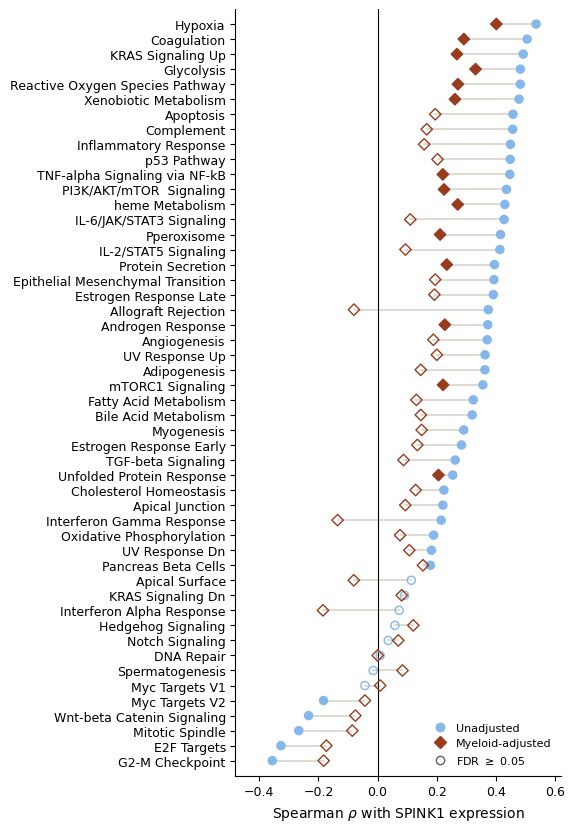

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'font.size': 9, 'axes.labelsize': 10, 'axes.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'pdf.fonttype': 42})
C_RAW, C_ADJ = '#85B7EB', '#993C1D'

d = s6.sort_values('rho_raw').reset_index(drop=True)
y = np.arange(len(d))
sig_raw, sig_adj = d['FDR_raw'] < 0.05, d['FDR_adj_myeloid'] < 0.05

fig, ax = plt.subplots(figsize=(5.8, 8.4))
for i in y:
    ax.plot([d.at[i, 'rho_raw'], d.at[i, 'rho_adj_myeloid']], [i, i],
            color='#D3D1C7', lw=1.1, zorder=1)
ax.scatter(d['rho_raw'], y, s=34, marker='o', zorder=3, linewidths=1.0,
           facecolors=np.where(sig_raw, C_RAW, 'none'), edgecolors=C_RAW)
ax.scatter(d['rho_adj_myeloid'], y, s=34, marker='D', zorder=3, linewidths=1.0,
           facecolors=np.where(sig_adj, C_ADJ, 'none'), edgecolors=C_ADJ)
ax.axvline(0, color='black', lw=0.8, zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(d['pathway'])
ax.set_ylim(-1, len(d))
ax.set_xlim(-0.48, 0.62)
ax.set_xlabel('Spearman $\\rho$ with SPINK1 expression')
ax.legend(handles=[
    Line2D([], [], marker='o', ls='', mfc=C_RAW, mec=C_RAW, ms=6, label='Unadjusted'),
    Line2D([], [], marker='D', ls='', mfc=C_ADJ, mec=C_ADJ, ms=6, label='Myeloid-adjusted'),
    Line2D([], [], marker='o', ls='', mfc='none', mec='#5F5E5A', ms=6, label='FDR $\\geq$ 0.05')],
    loc='lower right', fontsize=8, handletextpad=0.4)
fig.tight_layout()

for ext in ['png', 'pdf']:
    fig.savefig(os.path.join(RESULTS, f'Figure_2_hallmark_pathway_landscape.{ext}'),
                dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
SUBTYPES = list(SUBTYPE_PANELS)
sub = pd.DataFrame({k: panel_score(L, genes) for k, genes in SUBTYPE_PANELS.items()})
subtype = ((sub - sub.mean()) / sub.std(ddof=0)).idxmax(axis=1)
spink1 = scores['SPINK1']

summary = pd.DataFrame({'n': subtype.value_counts(),
                        'median_SPINK1': spink1.groupby(subtype).median().round(2),
                        'pct_undetectable': (spink1.eq(0).groupby(subtype).mean() * 100).round(1)})
print(summary.reindex(SUBTYPES).to_string())
H, p = kruskal(*[spink1[subtype == k] for k in SUBTYPES])
print(f'Kruskal-Wallis p = {p:.2e}')
for k in SUBTYPES:
    r, p = spearmanr(spink1, sub[k])
    print(f'SPINK1 vs {k} score: rho = {r:.3f}, p = {p:.2e}')

              n  median_SPINK1  pct_undetectable
Proneural    45           1.06              35.6
Classical    51           0.00              60.8
Mesenchymal  48           2.25              18.8
Kruskal-Wallis p = 7.97e-06
SPINK1 vs Proneural score: rho = -0.104, p = 2.17e-01
SPINK1 vs Classical score: rho = -0.350, p = 1.66e-05
SPINK1 vs Mesenchymal score: rho = 0.438, p = 3.92e-08


In [ ]:
TARGETS = ['BUFFA_HYPOXIA_SCORE', 'WINTER_HYPOXIA_SCORE', 'Hallmark_Hypoxia']
PUBLISHED = ['BUFFA_HYPOXIA_SCORE', 'WINTER_HYPOXIA_SCORE', 'RAGNUM_HYPOXIA_SCORE']
df = scores.join(coh[PUBLISHED]).dropna().join(sub).join(subtype.rename('subtype'))

strat = []
for st in SUBTYPES:
    d = df[df['subtype'] == st]
    for t in TARGETS:
        r, p = spearmanr(d['SPINK1'], d[t])
        strat.append({'subtype': st, 'n': len(d), 'score': t.replace('_HYPOXIA_SCORE', ''),
                      'rho': round(r, 3), 'p': round(p, 4)})

full = []
for t in TARGETS:
    r0, p0 = spearmanr(df['SPINK1'], df[t])
    rf, pf = partial_spearman(df['SPINK1'], df[t], df[['Myeloid', 'Mesenchymal', 'Proliferation']])
    full.append({'hypoxia_score': t, 'n': len(df), 'rho_raw': round(r0, 3), 'p_raw': f'{p0:.2e}',
                 'rho_full_adj': round(rf, 3), 'p_full_adj': f'{pf:.4f}'})

strat, full = pd.DataFrame(strat), pd.DataFrame(full)
s7 = pd.concat([strat.assign(analysis='stratified'), full.assign(analysis='full_model')],
               ignore_index=True)
s7.to_csv(os.path.join(RESULTS, 'Table_S7_subtype_hypoxia.csv'), index=False)

print('n =', len(df))
print(strat.pivot(index='score', columns='subtype', values='rho').to_string())
print(full.to_string(index=False))

n = 143
subtype           Classical  Mesenchymal  Proneural
score                                              
BUFFA                 0.294        0.200      0.269
Hallmark_Hypoxia      0.445        0.415      0.476
WINTER                0.331        0.339      0.264
       hypoxia_score   n  rho_raw    p_raw  rho_full_adj p_full_adj
 BUFFA_HYPOXIA_SCORE 143    0.351 1.70e-05         0.299     0.0003
WINTER_HYPOXIA_SCORE 143    0.363 8.49e-06         0.319     0.0001
    Hallmark_Hypoxia 143    0.530 9.84e-12         0.382     0.0000


In [ ]:
mes_clean = [g for g in SUBTYPE_PANELS['Mesenchymal'] if g not in set(lib['Hypoxia'])]
print('Removed from mesenchymal panel:', sorted(set(SUBTYPE_PANELS['Mesenchymal']) - set(mes_clean)))
df['Mes_clean'] = panel_score(L, mes_clean)

rows = []
for t in TARGETS:
    r0, _ = spearmanr(df['SPINK1'], df[t])
    r1, p1 = partial_spearman(df['SPINK1'], df[t], df[['Myeloid', 'Mesenchymal', 'Proliferation']])
    r2, p2 = partial_spearman(df['SPINK1'], df[t], df[['Myeloid', 'Mes_clean', 'Proliferation']])
    rows.append({'hypoxia_score': t.replace('_HYPOXIA_SCORE', ''), 'n': len(df),
                 'rho_raw': round(r0, 3), 'rho_adj_original': round(r1, 3), 'p_original': f'{p1:.4f}',
                 'rho_adj_clean': round(r2, 3), 'p_clean': f'{p2:.4f}'})

s8 = pd.DataFrame(rows)
s8.to_csv(os.path.join(RESULTS, 'Table_S8_mesenchymal_sensitivity.csv'), index=False)
print(s8.to_string(index=False))

Removed from mesenchymal panel: ['COL5A1', 'LOX', 'PLAUR', 'SERPINE1']
   hypoxia_score   n  rho_raw  rho_adj_original p_original  rho_adj_clean p_clean
           BUFFA 143    0.351             0.299     0.0003          0.334  0.0001
          WINTER 143    0.363             0.319     0.0001          0.362  0.0000
Hallmark_Hypoxia 143    0.530             0.382     0.0000          0.429  0.0000
